### 이진 분류

In [1]:
import torch
import matplotlib.pyplot as plt

#### step 1. 데이터 생성

In [4]:
n = 20
r0 = torch.randn(int(n / 2), 1)
r5 = torch.randn(int(n / 2), 1) + 5
# data
c1d = torch.hstack([r0, r5])  # class1 data
c2d = torch.hstack([r5, r0])
# label
c1l = torch.ones(int(n / 2), 1)  # class1 label
c2l = torch.ones(int(n / 2), 1)
x = torch.vstack([c1d, c2d])
y = torch.vstack([c1l, c2l])

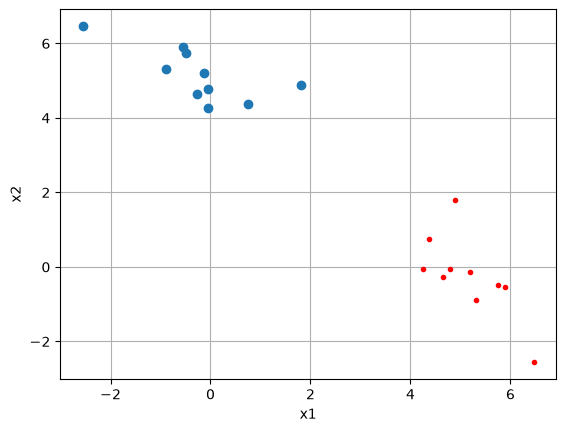

In [5]:
plt.plot(c1d[:, 0], c1d[:, 1], "o")
plt.plot(c2d[:, 0], c2d[:, 1], "r.")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid()

#### step 2. 모델 만들기

In [6]:
from torch import nn

In [15]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Sequential(
            nn.Linear(2, 100), nn.Sigmoid(), nn.Linear(100, 1), nn.Sigmoid()
        )

    def forward(self, x):
        x = self.linear(x)
        return x

In [16]:
m = MLP()
b = m(torch.randn(5, 2))
print(b.shape, b)

torch.Size([5, 1]) tensor([[0.4046],
        [0.4005],
        [0.3937],
        [0.4180],
        [0.4092]], grad_fn=<SigmoidBackward0>)


#### step 3. 모델 학습시키기

In [17]:
from torch import optim

In [18]:
LR = 1e-1
EPOCH = 100
op = optim.SGD(m.parameters(), lr=LR)
cr = nn.BCELoss()
lh = []
m.train()  # train mode로 전환
for ep in range(EPOCH):
    y_hat = m(x)
    loss = cr(y_hat, y)
    op.zero_grad()
    loss.backward()
    op.step()
    lh += [loss.item()]
    print(loss.item())

0.9204652905464172
0.22003504633903503
0.12721197307109833
0.09039570391178131
0.07035010308027267
0.05767205357551575
0.048906970769166946
0.042475856840610504
0.03755147382616997
0.033657439053058624
0.030499687418341637
0.027886610478162766
0.025688007473945618
0.023812126368284225
0.022192617878317833
0.020780101418495178
0.019537173211574554
0.018434960395097733
0.017450761049985886
0.016566550359129906
0.015767820179462433
0.015042709186673164
0.014381441287696362
0.013775983825325966
0.013219473883509636
0.012706254608929157
0.0122314328327775
0.011790827848017216
0.011380897834897041
0.010998539626598358
0.010641049593687057
0.010306084528565407
0.009991544298827648
0.009695672430098057
0.009416798129677773
0.009153514169156551
0.008904564194381237
0.008668797090649605
0.00844518281519413
0.00823281705379486
0.008030853234231472
0.007838582620024681
0.0076552750542759895
0.007480342872440815
0.007313212845474482
0.007153400219976902
0.007000413723289967
0.006853821687400341
0.0

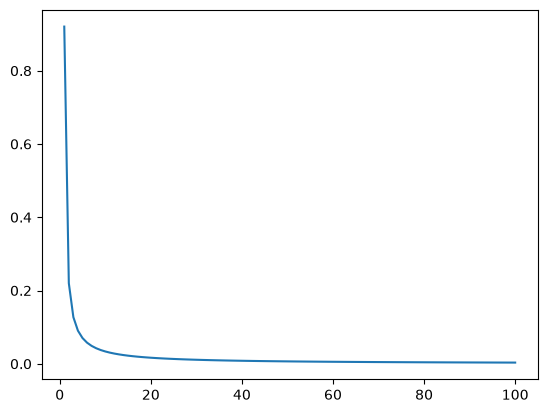

In [19]:
plt.plot(range(1, EPOCH + 1), lh)